In [7]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [8]:
graph_type = 'ER'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")


beta_uni = 0.255413, beta_SG = 0.549306


In [9]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/nb_star_DS_{graph_type}_{coup_type}_d{d}_N*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique())
df

betas: [0.24 0.25 0.26 0.27] 
sizes: [ 10000 100000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,time,mean_nb_star,std_nb_star,mean_nb_confs,std_nb_confs
0,0.24,F_beta_Glauber,False,2,50,100000000,10000,50,1,5007.66,52.169574,1.0,0.0
1,0.24,F_beta_Glauber,False,2,50,100000000,10000,50,2,5007.34,52.236619,1.0,0.0
2,0.24,F_beta_Glauber,False,2,50,100000000,10000,50,3,5007.06,52.197858,1.0,0.0
3,0.24,F_beta_Glauber,False,2,50,100000000,10000,50,4,5006.82,52.164237,1.0,0.0
4,0.24,F_beta_Glauber,False,2,50,100000000,10000,50,5,5006.64,52.292929,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6691,0.27,F_beta_Glauber,False,2,50,100000000,100000,0,92889787,1660.08,231.280595,1.0,0.0
6692,0.27,F_beta_Glauber,False,2,50,100000000,100000,0,94618482,1666.76,246.309850,1.0,0.0
6693,0.27,F_beta_Glauber,False,2,50,100000000,100000,0,96379348,1669.96,232.904183,1.0,0.0
6694,0.27,F_beta_Glauber,False,2,50,100000000,100000,0,98172984,1675.60,247.302163,1.0,0.0


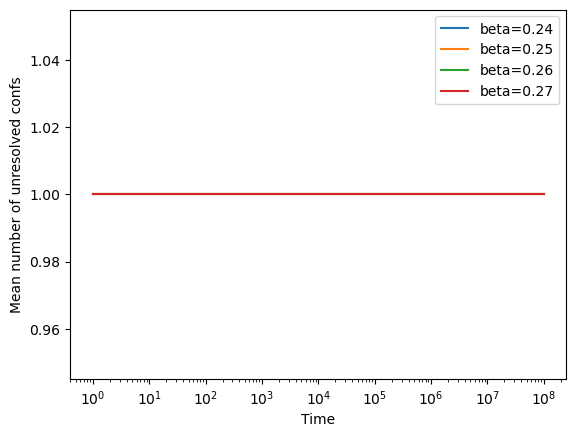

In [14]:
N_plotted = 10**5
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_confs'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_confs'] - sub_df['std_nb_confs'],
                     sub_df['mean_nb_confs'] + sub_df['std_nb_confs'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of unresolved confs')
plt.legend()
plt.show()

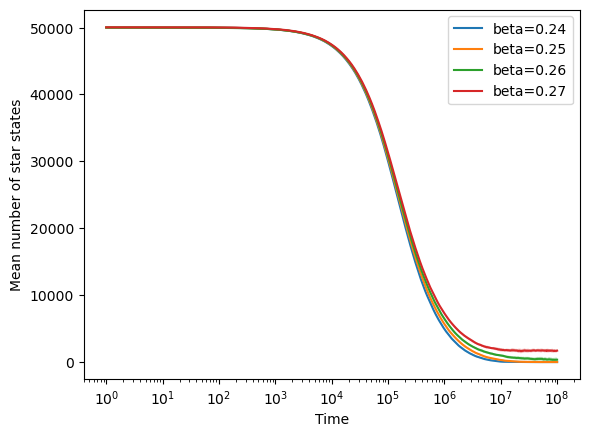

In [15]:
for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()